## write a python program to generate image histograms and perform histogram equalization.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read image
img = cv2.imread('image.jpeg')

# Convert BGR to RGB
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Convert RGB to grayscale
gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)


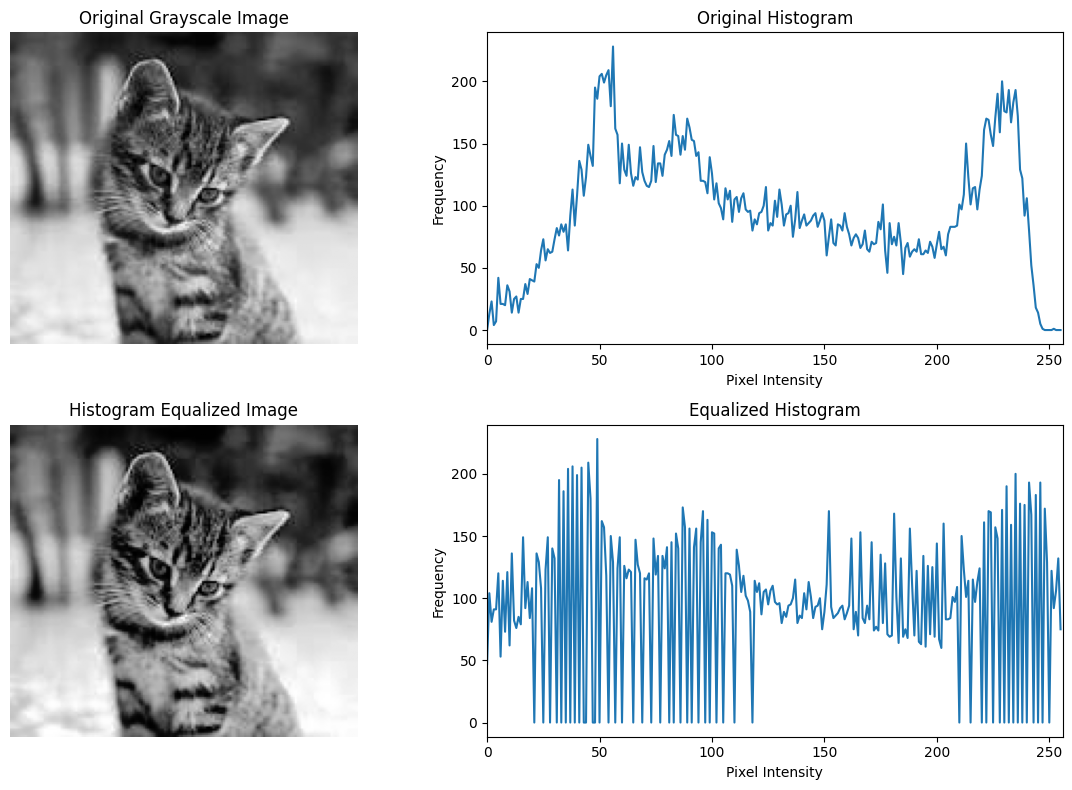

In [2]:

# 1. Generate Histogram
hist = cv2.calcHist([gray], [0], None, [256], [0, 256])

# 2. Histogram Equalization
equalized = cv2.equalizeHist(gray)

# Generate equalized histogram
hist_equalized = cv2.calcHist([equalized], [0], None, [256], [0, 256])

# Display results
plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.imshow(gray, cmap='gray')
plt.title('Original Grayscale Image')
plt.axis('off')

plt.subplot(2, 2, 2)
plt.plot(hist)
plt.title('Original Histogram')
plt.xlabel('Pixel Intensity')
plt.ylabel('Frequency')
plt.xlim([0, 256])

plt.subplot(2, 2, 3)
plt.imshow(equalized, cmap='gray')
plt.title('Histogram Equalized Image')
plt.axis('off')

plt.subplot(2, 2, 4)
plt.plot(hist_equalized)
plt.title('Equalized Histogram')
plt.xlabel('Pixel Intensity')
plt.ylabel('Frequency')
plt.xlim([0, 256])

plt.tight_layout()
plt.show()

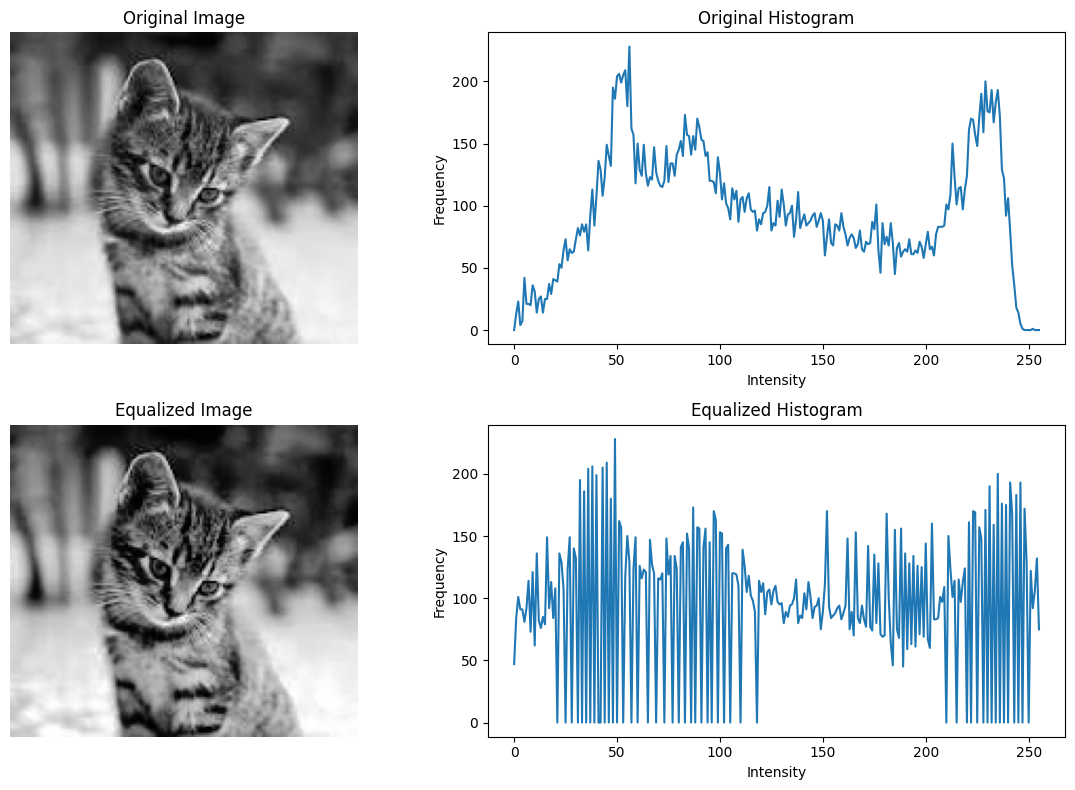

In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read image
img = cv2.imread('image.jpeg')

# Convert BGR to RGB
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Convert to grayscale
gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

# Get image dimensions
rows, cols = gray.shape

# ---------------------------------
# 1. MANUAL HISTOGRAM GENERATION
# ---------------------------------

hist = np.zeros(256, dtype=int)

for i in range(rows):
    for j in range(cols):
        intensity = gray[i, j]
        hist[intensity] += 1

# ---------------------------------
# 2. MANUAL HISTOGRAM EQUALIZATION
# ---------------------------------

# Calculate PDF (Probability Distribution Function)
pdf = hist / (rows * cols)

# Calculate CDF (Cumulative Distribution Function)
cdf = np.zeros(256)

cdf[0] = pdf[0]

for i in range(1, 256):
    cdf[i] = cdf[i-1] + pdf[i]

# Find minimum non-zero CDF
cdf_min = cdf[cdf > 0].min()

# Create intensity mapping table
mapping = np.zeros(256, dtype=np.uint8)

for i in range(256):
    mapping[i] = round(cdf[i] * 255)

# Apply mapping to original image
equalized = np.zeros_like(gray)

for i in range(rows):
    for j in range(cols):
        equalized[i, j] = mapping[gray[i, j]]

# ---------------------------------
# 3. GENERATE EQUALIZED HISTOGRAM
# ---------------------------------

hist_equalized = np.zeros(256, dtype=int)

for i in range(rows):
    for j in range(cols):
        intensity = equalized[i, j]
        hist_equalized[intensity] += 1

# ---------------------------------
# 4. DISPLAY RESULTS
# ---------------------------------

plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.imshow(gray, cmap='gray')
plt.title('Original Image')
plt.axis('off')

plt.subplot(2, 2, 2)
plt.plot(hist)
plt.title('Original Histogram')
plt.xlabel('Intensity')
plt.ylabel('Frequency')

plt.subplot(2, 2, 3)
plt.imshow(equalized, cmap='gray')
plt.title('Equalized Image')
plt.axis('off')

plt.subplot(2, 2, 4)
plt.plot(hist_equalized)
plt.title('Equalized Histogram')
plt.xlabel('Intensity')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()